<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Which shift contains an event at the boundary?

Join NHL play-by-play times to recorded player shifts, then change the interval endpoint policy. A goal exactly at a shift end makes the choice visible. The investigation follows **Brad Marchand (8473419)** in **period 1 of game 2025020001**, Chicago at Florida on **2025-10-07**.

**Default: unchanged, recorded and trimmed NHL responses from this repository’s tests.** The replay contains selected events and six shift rows for one player. It is incomplete game and lineup coverage; original capture timestamps are unavailable. An event without a matching recorded shift is not proof that the player was off the ice. This is an interval-join example, not an official on-ice attribution or player-performance assessment.

## Choose an explicit endpoint policy

`BOUNDARY_POLICY` accepts **"ending_shift"** (default), meaning `start < event ≤ end`, or **"starting_shift"**, meaning `start ≤ event < end`. Both are half-open interval conventions; neither establishes sub-second physical presence. The worker README uses the first convention.

`DATA_MODE` accepts **"replay"** or **"live"**. Both request the same historical game and select the same player and first period. Replay supports only those bundled endpoint requests. Restart and run all after editing a parameter.

In [1]:
DATA_MODE = "replay"
BOUNDARY_POLICY = "ending_shift"  # or "starting_shift"

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

from notebook_support import finish, theme
from recorded_api import configure

assert BOUNDARY_POLICY in {"ending_shift", "starting_shift"}
replay = configure(DATA_MODE)
run_at = datetime.now(UTC).isoformat(timespec="seconds")
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-nhl/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-nhl/notebooks/pyproject.toml.

## Materialize both sources once

The literal Git command pins a published worker revision and tested SDK versions. The replay server uses the worker’s supported URL overrides; the real worker still fetches and normalizes both responses through VGI. Live mode clears inherited overrides and never falls back to replay.

`play_by_play` returns event-clock seconds. `shift_chart` returns shift intervals and omits non-shift goal-marker rows in its source response. We restrict this example to regulation period 1, where both clocks share the same 0–1,200-second frame; no overtime clock assumptions are needed.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nhl' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --from git+https://github.com/Query-farm/vgi-nhl@d8aff6a88c64704047a3cd0a078c83a561de8633 vgi-nhl');
CREATE TABLE all_events AS SELECT * FROM nhl.main.play_by_play(2025020001);
CREATE TABLE all_shifts AS SELECT * FROM nhl.main.shift_chart(2025020001);
CREATE TABLE shifts AS SELECT * FROM all_shifts WHERE player_id=8473419 AND period=1;
CREATE TABLE events AS
SELECT * FROM all_events WHERE period=1 AND period_type='REG'
 AND event_type IN('goal','shot-on-goal','missed-shot','blocked-shot');

,Count


In [4]:
%%sql coverage <<
SELECT (SELECT count(*) FROM all_events) AS returned_events,
 (SELECT count(*) FROM all_shifts) AS returned_shifts,
 (SELECT count(DISTINCT player_id) FROM all_shifts) AS returned_players,
 (SELECT count(*) FROM events) AS selected_shot_events,
 count(*) AS selected_shifts,sum(duration_seconds) AS recorded_shift_seconds,
 min(start_seconds) AS first_shift_start,max(end_seconds) AS last_shift_end
FROM shifts;

In [5]:
display(coverage)
assert int(coverage.selected_shifts.iloc[0]) > 0, "No recorded shifts for this player and period"
assert int(coverage.selected_shot_events.iloc[0]) > 0, "No selected shot events"
mode_label = "recorded subset" if DATA_MODE == "replay" else "live response"
display(
    Markdown(
        f"The **{mode_label}** returns **{int(coverage.returned_events.iloc[0])} events** and "
        f"**{int(coverage.returned_shifts.iloc[0])} shifts** "
        f"across **{int(coverage.returned_players.iloc[0])} "
        f"player{'s' if int(coverage.returned_players.iloc[0]) != 1 else ''}**. "
        f"The selection keeps **{int(coverage.selected_shifts.iloc[0])} shifts**, totaling "
        f"**{int(coverage.recorded_shift_seconds.iloc[0])} recorded seconds**, and "
        f"**{int(coverage.selected_shot_events.iloc[0])} shot-related events**. "
        f"Run clock: **{run_at}** (UTC), not a source capture time. The two API responses are not an atomic snapshot."
    )
)

,returned_events,returned_shifts,returned_players,selected_shot_events,selected_shifts,recorded_shift_seconds,first_shift_start,last_shift_end
0,18,6,1,6,6,330.0,0,828


The **recorded subset** returns **18 events** and **6 shifts** across **1 player**. The selection keeps **6 shifts**, totaling **330 recorded seconds**, and **6 shot-related events**. Run clock: **2026-11-14T08:28:54+00:00** (UTC), not a source capture time. The two API responses are not an atomic snapshot.

## Compare both inequalities before choosing one

A left join preserves every selected event. Count matching shift IDs separately for each policy, rather than dropping unmatched events with an inner join. We also flag exact starts or ends. Multiple matches would signal overlapping or duplicated intervals needing review; they should not be silently collapsed into one confident attribution.

In [6]:
%%sql
CREATE TABLE event_matches AS
SELECT e.event_id,e.sort_order,e.event_type,e.game_seconds,e.time_in_period,
 e.event_owner_team_abbrev,e.primary_player_name,
 count(s.shift_id) FILTER(WHERE e.game_seconds>s.start_seconds AND e.game_seconds<=s.end_seconds) AS ending_matches,
 count(s.shift_id) FILTER(WHERE e.game_seconds>=s.start_seconds AND e.game_seconds<s.end_seconds) AS starting_matches,
 coalesce(bool_or(e.game_seconds=s.start_seconds OR e.game_seconds=s.end_seconds),false) AS exact_boundary
FROM events e LEFT JOIN shifts s ON e.game_id=s.game_id AND e.period=s.period
GROUP BY e.event_id,e.sort_order,e.event_type,e.game_seconds,e.time_in_period,e.event_owner_team_abbrev,e.primary_player_name;
CREATE TABLE classified AS
SELECT *,CASE WHEN '{{BOUNDARY_POLICY}}'='ending_shift' THEN ending_matches ELSE starting_matches END AS selected_matches
FROM event_matches;

,Count


In [7]:
%%sql match_table <<
SELECT event_id,event_type,time_in_period,event_owner_team_abbrev,primary_player_name,
 ending_matches,starting_matches,exact_boundary,selected_matches
FROM classified ORDER BY sort_order;

In [8]:
display(match_table)

,event_id,event_type,time_in_period,event_owner_team_abbrev,primary_player_name,ending_matches,starting_matches,exact_boundary,selected_matches
0,101,blocked-shot,00:22,FLA,Brad Marchand,1,1,False,1
1,71,shot-on-goal,01:16,FLA,Evan Rodrigues,0,0,False,0
2,80,missed-shot,01:44,CHI,Connor Bedard,0,0,False,0
3,258,goal,10:03,CHI,Frank Nazar,1,0,True,1
4,274,goal,11:06,FLA,A.J. Greer,0,0,False,0
5,366,goal,14:08,FLA,Carter Verhaeghe,0,0,False,0


## Put intervals and events on the same clock

Bars show returned shifts only. Event markers sit on a separate lane, with dashed vertical guides at exact shift boundaries. Marker type identifies the selected event category. Open versus filled endpoints are a join convention; the underlying recorded timestamps and durations do not change with the policy.

In [9]:
%%sql intervals <<
SELECT shift_id,shift_number,start_seconds,end_seconds,duration_seconds,start_time,end_time FROM shifts ORDER BY start_seconds;

In [10]:
%%sql markers <<
SELECT event_id,event_type,game_seconds,time_in_period,exact_boundary FROM classified ORDER BY sort_order;

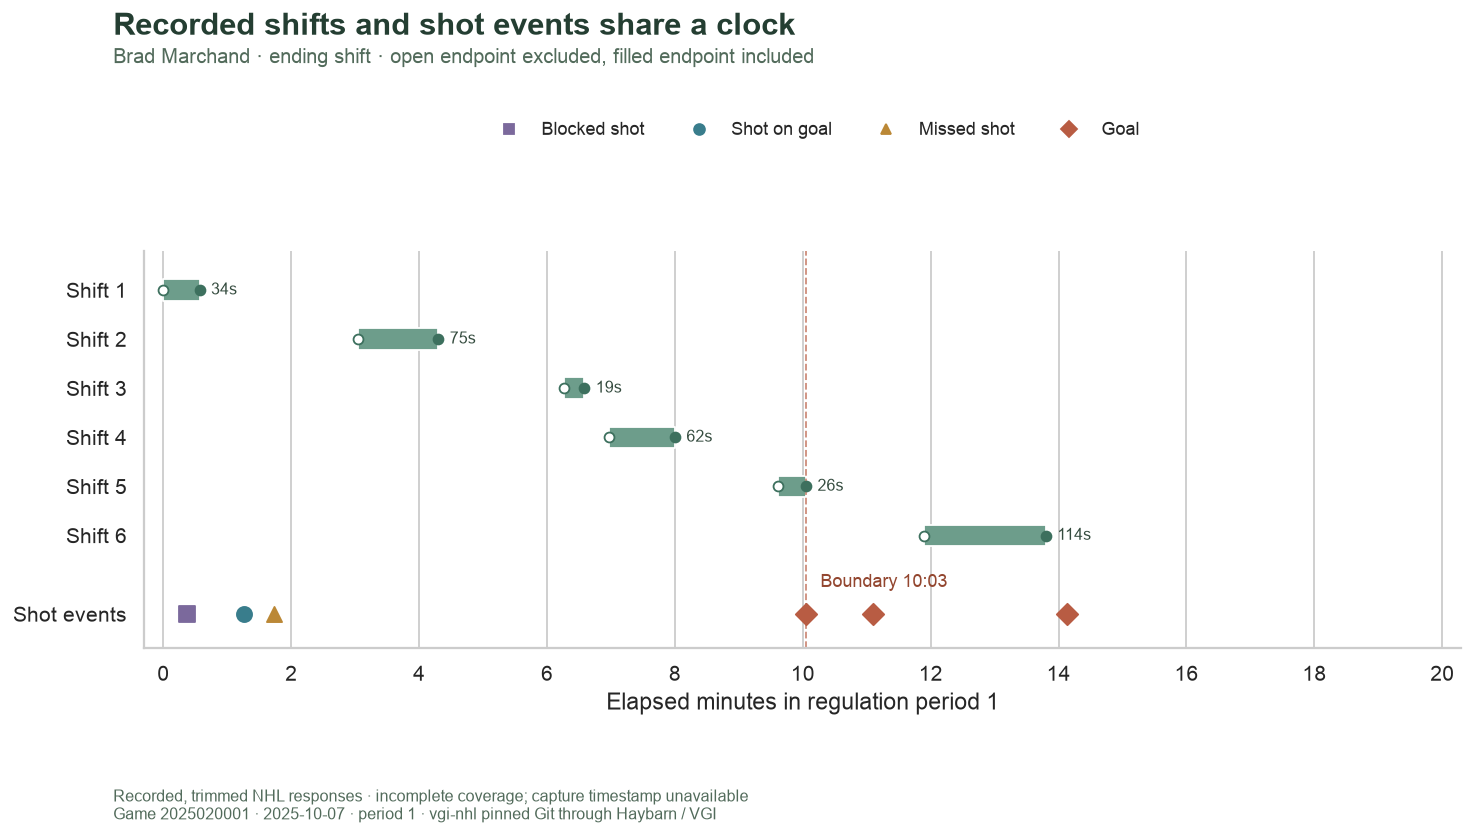

In [11]:
event_style = {
    "blocked-shot": ("s", "#7b699c", "Blocked shot"),
    "shot-on-goal": ("o", "#397d8c", "Shot on goal"),
    "missed-shot": ("^", "#bb8836", "Missed shot"),
    "goal": ("D", "#b85c43", "Goal"),
}
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, row in enumerate(intervals.itertuples()):
    ax.broken_barh([(row.start_seconds / 60, row.duration_seconds / 60)], (i - 0.22, 0.44), facecolors="#6d9d8b")
    ax.text(
        row.end_seconds / 60 + 0.18,
        i,
        f"{row.duration_seconds}s",
        ha="left",
        va="center",
        fontsize=9,
        color="#344b3e",
    )
    if BOUNDARY_POLICY == "ending_shift":
        open_end, closed_end = row.start_seconds, row.end_seconds
    else:
        open_end, closed_end = row.end_seconds, row.start_seconds
    ax.scatter(open_end / 60, i, s=30, facecolors="white", edgecolors="#3d705e", zorder=4)
    ax.scatter(closed_end / 60, i, s=30, facecolors="#3d705e", edgecolors="#3d705e", zorder=4)
    event_y = len(intervals) + 0.6
for row in markers.itertuples():
    marker, color, label = event_style[row.event_type]
    ax.scatter(row.game_seconds / 60, event_y, s=70, marker=marker, color=color, zorder=4)
    if row.exact_boundary:
        ax.axvline(row.game_seconds / 60, color="#b85c43", linestyle="--", linewidth=1, alpha=0.7)
        ax.annotate(
            f"Boundary {row.time_in_period}",
            (row.game_seconds / 60, event_y),
            xytext=(8, 15),
            textcoords="offset points",
            fontsize=10,
            color="#93462f",
        )
ax.set_yticks(list(range(len(intervals))) + [event_y], [f"Shift {v}" for v in intervals.shift_number] + ["Shot events"])
ax.set_ylim(event_y + 0.7, -0.8)
ax.set_xlim(-0.3, 20.3)
ax.set_xticks(range(0, 21, 2))
ax.set_xlabel("Elapsed minutes in regulation period 1")
ax.grid(axis="y", visible=False)
handles = [
    Line2D([0], [0], marker=shape, color=color, linestyle="", label=label)
    for shape, color, label in event_style.values()
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=4, frameon=False, fontsize=10)
finish(
    fig,
    f"timeline-{BOUNDARY_POLICY}",
    "Recorded shifts and shot events share a clock",
    f"Brad Marchand · {BOUNDARY_POLICY.replace('_', ' ')} · open endpoint excluded, filled endpoint included",
    DATA_MODE,
)

## Keep unmatched events in the denominator

The bars partition selected events by the chosen policy. “No matching recorded shift” describes the available interval relation; especially in replay, it does not mean “off ice.” A shot, goal or team label also does not assign responsibility to the selected player. The comparison measures join behavior, not player impact.

In [12]:
%%sql event_counts <<
SELECT event_type,count(*) AS events,
 count(*) FILTER(WHERE selected_matches>0) AS matching,
 count(*) FILTER(WHERE selected_matches=0) AS unmatched
FROM classified GROUP BY event_type ORDER BY event_type;

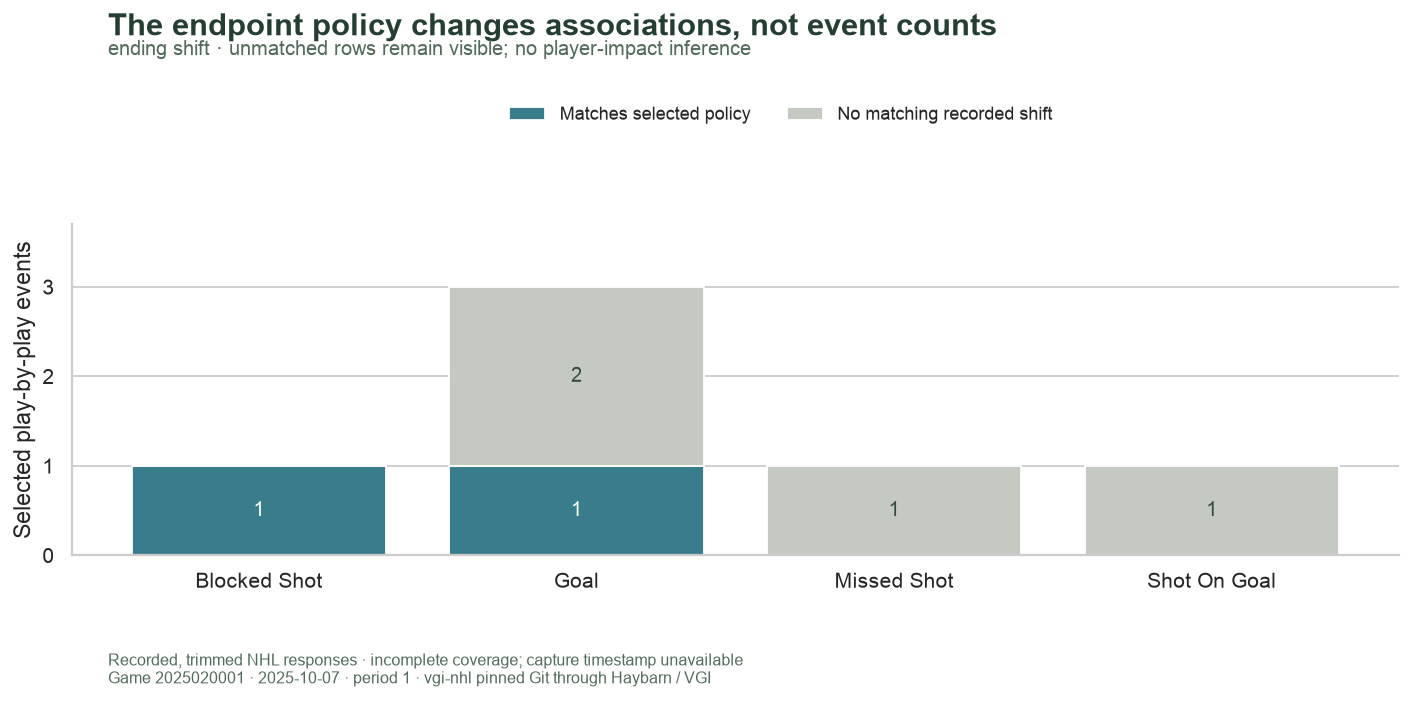

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 5.4))
x = list(range(len(event_counts)))
first = ax.bar(x, event_counts.matching, color="#397d8c", label="Matches selected policy")
second = ax.bar(
    x, event_counts.unmatched, bottom=event_counts.matching, color="#c4c9c2", label="No matching recorded shift"
)
ax.bar_label(
    first, labels=[str(v) if v else "" for v in event_counts.matching], label_type="center", color="white", fontsize=11
)
ax.bar_label(
    second,
    labels=[str(v) if v else "" for v in event_counts.unmatched],
    label_type="center",
    color="#344b3e",
    fontsize=11,
)
ax.set_xticks(x, [v.replace("-", " ").title() for v in event_counts.event_type])
ax.set_ylabel("Selected play-by-play events")
ax.set_ylim(0, float(event_counts.events.max()) + 0.7)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False, fontsize=10
)
finish(
    fig,
    f"matches-{BOUNDARY_POLICY}",
    "The endpoint policy changes associations, not event counts",
    f"{BOUNDARY_POLICY.replace('_', ' ')} · unmatched rows remain visible; no player-impact inference",
    DATA_MODE,
)

In [14]:
changed = match_table[match_table.ending_matches != match_table.starting_matches]
matched = int((match_table.selected_matches > 0).sum())
display(
    Markdown(
        f"The chosen policy matches **{matched} of {len(match_table)} events** to at least one recorded shift. "
        f"The two policies disagree for **{len(changed)} event{'s' if len(changed) != 1 else ''}**; "
        "all checked below for an exact interval boundary. "
        "Their event times and recorded shift seconds remain identical. "
        "A boundary convention determines the SQL association; "
        "it does not recover finer-grained timing or missing shift coverage."
    )
)
if not changed.empty:
    display(changed[["event_id", "event_type", "time_in_period", "ending_matches", "starting_matches"]])

The chosen policy matches **2 of 6 events** to at least one recorded shift. The two policies disagree for **1 event**; all checked below for an exact interval boundary. Their event times and recorded shift seconds remain identical. A boundary convention determines the SQL association; it does not recover finer-grained timing or missing shift coverage.

,event_id,event_type,time_in_period,ending_matches,starting_matches
3,258,goal,10:03,1,0


## Check interval and join accounting

Validate first-period clocks, unique records, positive durations, non-overlapping selected shifts, complete event retention and policy disagreement only at exact boundaries. These checks do not require a fixed fixture count or a particular game result. A missing source or absent selection fails visibly.

In [15]:
%%sql checks <<
SELECT 'selected event IDs are unique' AS check_name,count(*)=count(DISTINCT event_id) AS passed FROM events
UNION ALL SELECT 'selected shift IDs are unique',count(*)=count(DISTINCT shift_id) FROM shifts
UNION ALL SELECT 'all selected records belong to the requested game',
 (SELECT bool_and(game_id=2025020001) FROM events) AND (SELECT bool_and(game_id=2025020001) FROM shifts)
UNION ALL SELECT 'first-period event clocks are within 0 to 1200 seconds',bool_and(game_seconds BETWEEN 0 AND 1200) FROM events
UNION ALL SELECT 'shift duration equals positive end minus start',bool_and(duration_seconds>0 AND end_seconds-start_seconds=duration_seconds AND start_seconds>=0 AND end_seconds<=1200) FROM shifts
UNION ALL SELECT 'selected shift interiors do not overlap',count(*)=0 FROM shifts a JOIN shifts b ON a.shift_id<b.shift_id AND a.start_seconds<b.end_seconds AND b.start_seconds<a.end_seconds
UNION ALL SELECT 'every selected event survives the join',count(*)=(SELECT count(*) FROM events) AND count(*)=count(DISTINCT event_id) FROM classified
UNION ALL SELECT 'each half-open policy matches at most one interval',bool_and(ending_matches<=1 AND starting_matches<=1) FROM classified
UNION ALL SELECT 'policies disagree only at exact boundaries',coalesce(bool_and(exact_boundary),true) FROM classified WHERE ending_matches<>starting_matches
UNION ALL SELECT 'selected policy is applied exactly',bool_and(selected_matches=CASE WHEN '{{BOUNDARY_POLICY}}'='ending_shift' THEN ending_matches ELSE starting_matches END) FROM classified
UNION ALL SELECT 'matched and unmatched counts partition selected events',sum(matching+unmatched)=(SELECT count(*) FROM events) FROM(
 SELECT count(*) FILTER(WHERE selected_matches>0) AS matching,count(*) FILTER(WHERE selected_matches=0) AS unmatched FROM classified);

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} checks** pass. Coverage and endpoint policy remain explicit alongside the join result."
    )
)

,check_name,passed
0,selected event IDs are unique,True
1,selected shift IDs are unique,True
2,all selected records belong to the requested game,True
3,first-period event clocks are within 0 to 1200...,True
4,shift duration equals positive end minus start,True
5,selected shift interiors do not overlap,True
6,every selected event survives the join,True
7,each half-open policy matches at most one inte...,True
8,policies disagree only at exact boundaries,True
9,selected policy is applied exactly,True


All **11 checks** pass. Coverage and endpoint policy remain explicit alongside the join result.

## Try one change

Change `BOUNDARY_POLICY` from **"ending_shift"** to **"starting_shift"**, restart and run all. Predict that the event exactly at a recorded shift end loses that match unless another recorded interval starts there. Compare the boundary table and event-count chart; shift durations and total event counts should stay fixed. Restore **"ending_shift"** for the saved default.

For public data, set `DATA_MODE = "live"`. The worker requests the same historical game from both NHL endpoints; more complete responses can add events and shifts, so replay association counts need not persist. Failed requests are never replaced with fixtures. Source data and its usage conditions are described in the repository README; the notebook makes no claim to official scoring or causal player evaluation.

In [17]:
connection.close()
if replay is not None:
    replay.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>